# Cuaderno 01 — Exploración de los conjuntos de datos

**Tarea de ejecución 03 — Aplicar modelos CART y ensamblados**

**Curso:** Aprendizaje de Máquina (UNAP, IX ciclo, grupo B)
**Docente:** Ing. Fernández Chambi Mayenka
**Estudiante:** Cristian Junior Cunurana Calderón

---

## Objetivo de este cuaderno

Explorar y caracterizar los dos conjuntos de datos empleados en la práctica antes de
entrenar cualquier modelo:

1. **`breast_cancer`** (incluido en scikit-learn): clasificación binaria con 30 variables
   morfológicas de citología mamaria y 569 observaciones. Se usa en los ejercicios 1, 3, 4 y 5.
2. **`auto_mpg`** (UCI Machine Learning Repository): regresión con 398 vehículos y 7 variables
   predictoras. Se usa en el ejercicio 2 y en la variante regresora del ejercicio 4.

## Procedimiento

- Verificación del entorno de ejecución (versiones de Python y de las bibliotecas).
- Carga de los datos y control de la integridad (dimensiones, duplicados, valores faltantes).
- Análisis descriptivo univariante y bivariante de cada conjunto.
- Definición explícita de las particiones de entrenamiento y prueba y del esquema de
  preprocesamiento, con el fin de evitar fuga de información.

Las salidas de este cuaderno alimentan los cuadernos 02 y 03, donde se entrenan y evalúan los
modelos.

In [1]:
import sys
from pathlib import Path

# La raíz del proyecto se resuelve desde la ubicación del propio módulo `comun`,
# de modo que el cuaderno funciona igual ejecutado desde la raíz del repositorio
# o desde la carpeta `cuadernos/`.
sys.path.insert(0, str(Path.cwd() / "cuadernos"))
if not (Path.cwd() / "cuadernos" / "comun.py").exists():
    sys.path.insert(0, str(Path.cwd().parent / "cuadernos"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from comun import (
    RAIZ,
    SEMILLA,
    PALETA,
    aplicar_estilo,
    cargar_auto_mpg,
    cargar_breast_cancer,
    fijar_semilla,
    guardar_csv,
)

aplicar_estilo()
fijar_semilla(SEMILLA)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

print("RAIZ del proyecto:", RAIZ)

RAIZ del proyecto: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 3


# 1. Entorno de ejecución

Se registran las versiones exactas de las bibliotecas para que el experimento sea reproducible.

In [2]:
import platform
import sklearn
import scipy
import matplotlib
import seaborn as sns

try:
    import xgboost

    version_xgb = xgboost.__version__
except ImportError:  # pragma: no cover
    version_xgb = "no instalado"

print(f"Python .............. {platform.python_version()} ({platform.system()})")
print(f"NumPy ............... {np.__version__}")
print(f"Pandas .............. {pd.__version__}")
print(f"SciPy ............... {scipy.__version__}")
print(f"scikit-learn ........ {sklearn.__version__}")
print(f"XGBoost ............. {version_xgb}")
print(f"Matplotlib .......... {matplotlib.__version__}")
print(f"Seaborn ............. {sns.__version__}")
print(f"Semilla global ...... {SEMILLA}")

Python .............. 3.14.8 (Linux)
NumPy ............... 2.5.4
Pandas .............. 3.0.6
SciPy ............... 1.18.1
scikit-learn ........ 1.9.1
XGBoost ............. 3.4.1
Matplotlib .......... 3.11.2
Seaborn ............. 0.13.2
Semilla global ...... 42


# 2. Conjunto de datos `breast_cancer`

### 2.1 Carga y verificación de integridad

El conjunto viene distribuido con scikit-learn, por lo que no requiere descarga y su
reproducibilidad está garantizada por la versión de la biblioteca.

In [3]:
X_bc, y_bc, nombres_bc = cargar_breast_cancer()

df_bc = pd.DataFrame(X_bc, columns=nombres_bc)
df_bc.insert(0, "diagnostico", np.where(y_bc == 1, "maligno", "benigno"))

print("Dimensiones (filas, columnas):", df_bc.shape)
print("Duplicados:", int(df_bc.duplicated().sum()))
print("Valores faltantes:", int(df_bc.isna().sum().sum()))
print("Rango de valores: [{:.4f}, {:.4f}]".format(df_bc[nombres_bc].to_numpy().min(),
                                                 df_bc[nombres_bc].to_numpy().max()))
print("\nPrimeras tres observaciones:")
display(df_bc.head(3))

Dimensiones (filas, columnas): (569, 31)
Duplicados: 0
Valores faltantes: 0
Rango de valores: [0.0000, 4254.0000]

Primeras tres observaciones:


,diagnostico,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,benigno,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,benigno,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,benigno,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758


## 2.2 Distribución de la variable objetivo

La clase positiva se define como **maligno (1)**, porque es la que interesa detectar en
un diagnóstico. Las métricas de la práctica (precisión, exhaustividad y F1) se calculan
con esa clase como positiva.

In [4]:
conteo = df_bc["diagnostico"].value_counts()
proporciones = 100 * conteo / len(df_bc)
print(pd.DataFrame({"observaciones": conteo, "porcentaje": proporciones.round(2)}))

             observaciones  porcentaje
diagnostico                           
maligno                357       62.74
benigno                212       37.26


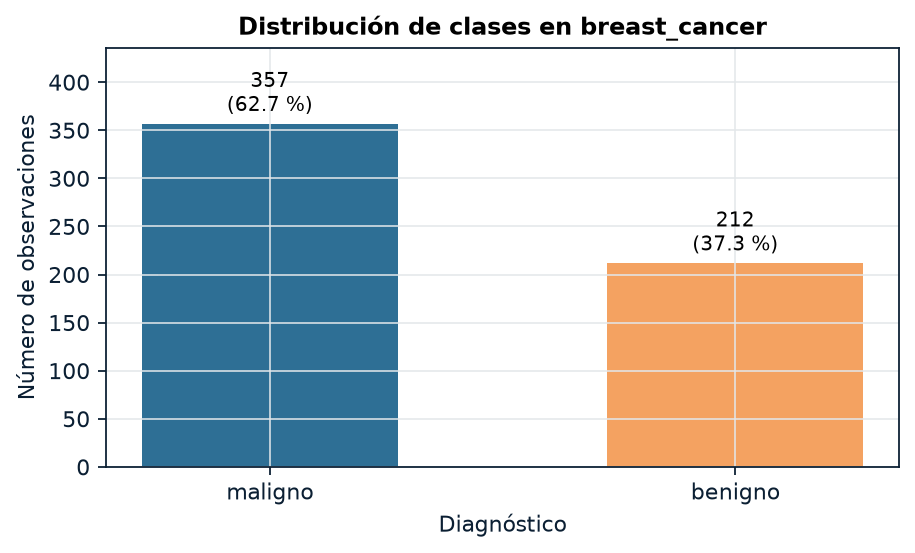

In [5]:
fig, ax = plt.subplots(figsize=(6.4, 3.4))
barras = ax.bar(
    conteo.index,
    conteo.values,
    color=[PALETA["azul_claro"], PALETA["naranja"]],
    width=0.55,
)
ax.set_ylabel("Número de observaciones")
ax.set_xlabel("Diagnóstico")
ax.set_title("Distribución de clases en breast_cancer")
ax.set_ylim(0, conteo.max() * 1.22)
for barra, valor, pct in zip(barras, conteo.values, proporciones.values):
    ax.text(barra.get_x() + barra.get_width() / 2, valor + 6,
            f"{valor}\n({pct:.1f} %)", ha="center", va="bottom", fontsize=9)
fig.savefig(RAIZ / "figuras" / "grafico_01_distribucion_clases.png")
plt.show()

## 2.3 Estadísticas descriptivas de las variables predictoras

In [6]:
desc = df_bc[nombres_bc].describe().T
desc["rango"] = desc["max"] - desc["min"]
desc["asimetria"] = df_bc[nombres_bc].skew()
print(desc[["mean", "std", "min", "max", "rango", "asimetria"]].round(4))

                             mean       std       min        max      rango  asimetria
mean radius               14.1273    3.5240    6.9810    28.1100    21.1290     0.9424
mean texture              19.2896    4.3010    9.7100    39.2800    29.5700     0.6504
mean perimeter            91.9690   24.2990   43.7900   188.5000   144.7100     0.9907
mean area                654.8891  351.9141  143.5000  2501.0000  2357.5000     1.6457
mean smoothness            0.0964    0.0141    0.0526     0.1634     0.1108     0.4563
mean compactness           0.1043    0.0528    0.0194     0.3454     0.3260     1.1901
mean concavity             0.0888    0.0797    0.0000     0.4268     0.4268     1.4012
mean concave points        0.0489    0.0388    0.0000     0.2012     0.2012     1.1712
mean symmetry              0.1812    0.0274    0.1060     0.3040     0.1980     0.7256
mean fractal dimension     0.0628    0.0071    0.0500     0.0974     0.0475     1.3045
radius error               0.4052    0.2773

## 2.4 Correlación con la variable objetivo

Se calcula la correlación de Pearson con la variable binaria codificada como 0/1. Sirve
para interpretar la importancia que asignan los modelos basados en árboles, pero
**no se utiliza para construir el modelo**: la selección de variables se deixa al
proceso de aprendizaje.

In [7]:
correlaciones = (
    df_bc[nombres_bc].corrwith(df_bc["diagnostico"].map({"benigno": 0, "maligno": 1}))
    .sort_values(key=lambda s: s.abs(), ascending=False)
)
print("Correlación de Pearson con la clase (ordenada por valor absoluto):")
print(correlaciones.round(4).to_string())

Correlación de Pearson con la clase (ordenada por valor absoluto):
worst concave points      -0.7936
worst perimeter           -0.7829
mean concave points       -0.7766
worst radius              -0.7765
mean perimeter            -0.7426
worst area                -0.7338
mean radius               -0.7300
mean area                 -0.7090
mean concavity            -0.6964
worst concavity           -0.6596
mean compactness          -0.5965
worst compactness         -0.5910
radius error              -0.5671
perimeter error           -0.5561
area error                -0.5482
worst texture             -0.4569
worst smoothness          -0.4215
worst symmetry            -0.4163
mean texture              -0.4152
concave points error      -0.4080
mean smoothness           -0.3586
mean symmetry             -0.3305
worst fractal dimension   -0.3239
compactness error         -0.2930
concavity error           -0.2537
fractal dimension error   -0.0780
smoothness error           0.0670
mean fractal di

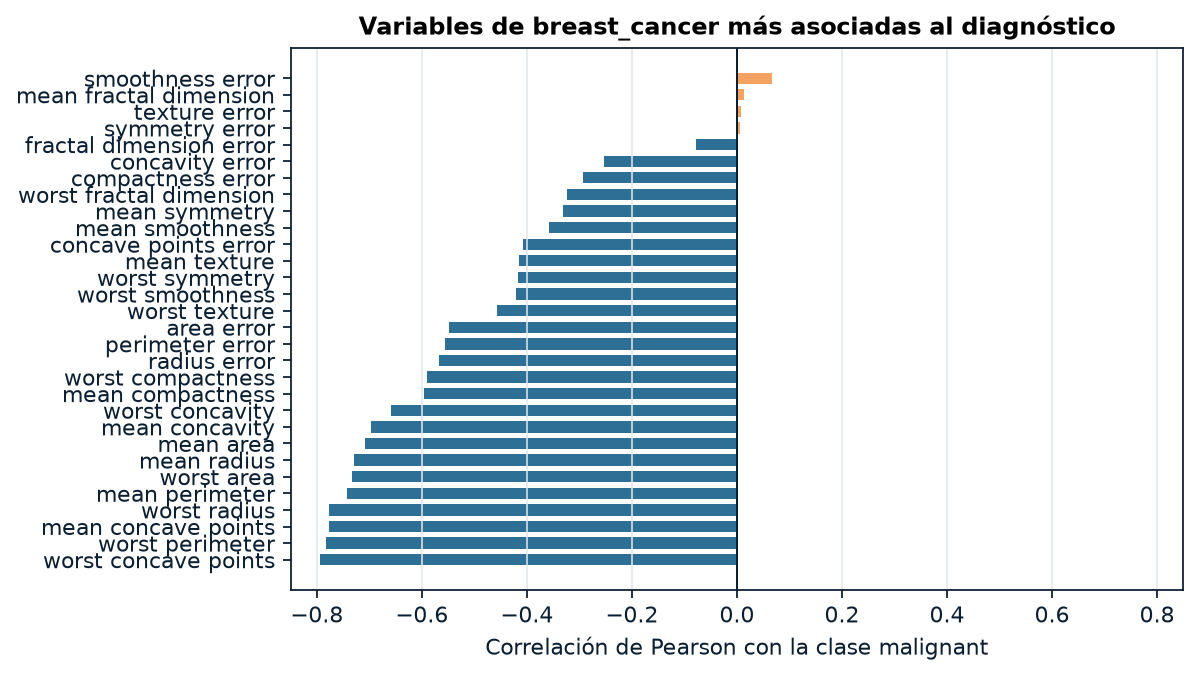

In [8]:
fig, ax = plt.subplots(figsize=(7.2, 4.4))
cor_plot = correlaciones.sort_values()
colores = [PALETA["naranja"] if v > 0 else PALETA["azul_claro"] for v in cor_plot.values]
ax.barh(cor_plot.index, cor_plot.values, color=colores, height=0.68)
ax.axvline(0, color=PALETA["azul_profundo"], linewidth=0.9)
ax.set_xlabel("Correlación de Pearson con la clase malignant")
ax.set_title("Variables de breast_cancer más asociadas al diagnóstico")
ax.set_xlim(-0.85, 0.85)
ax.grid(axis="y", visible=False)
fig.savefig(RAIZ / "figuras" / "grafico_02_correlaciones_breast_cancer.png")
plt.show()

## 2.5 Distribución de las variables con mayor poder discriminante

Se grafican las dos variables más correlacionadas (`worst radius` y `worst concavity`),
separando la distribución de la clase maligna y la benigna. El solapamiento entre ambas
distribuciones explica por qué el problema no es trivialmente separable por un único umbral.

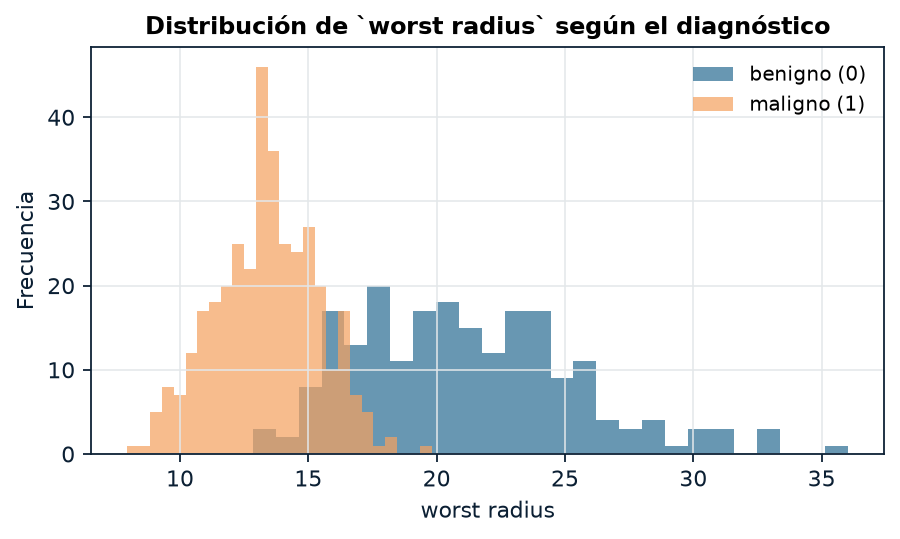

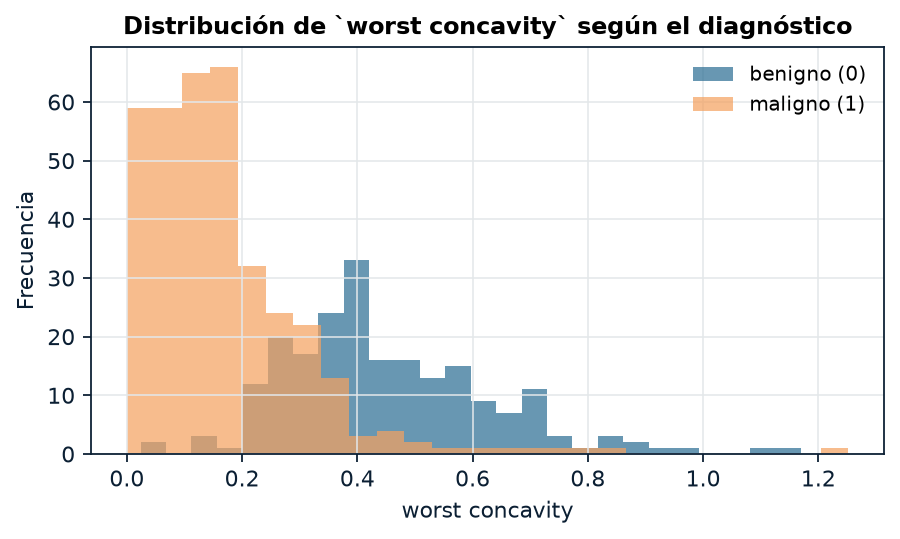

In [9]:
for i, variable in enumerate(["worst radius", "worst concavity"], start=3):
    fig, ax = plt.subplots(figsize=(6.4, 3.3))
    benigno = df_bc.loc[df_bc["diagnostico"] == "benigno", variable]
    maligno = df_bc.loc[df_bc["diagnostico"] == "maligno", variable]
    ax.hist(benigno, bins=26, alpha=0.72, label="benigno (0)", color=PALETA["azul_claro"])
    ax.hist(maligno, bins=26, alpha=0.72, label="maligno (1)", color=PALETA["naranja"])
    ax.set_xlabel(variable)
    ax.set_ylabel("Frecuencia")
    ax.set_title(f"Distribución de `{variable}` según el diagnóstico")
    ax.legend()
    fig.savefig(RAIZ / "figuras" / f"grafico_{i:02d}_dist_{variable.replace(' ', '_')}.png")
    plt.show()

## 2.6 Particiones de entrenamiento y prueba

Se utiliza una partición estratificada 80/20 con semilla 42. La estratificación garantiza
que la proporción de clases malignas y benignas se mantenga en ambos conjuntos, lo que
resulta imprescindible en un conjunto desbalanceado como este (37,3 % de malignos).

In [10]:
from sklearn.model_selection import train_test_split

X_tr, X_te, y_tr, y_te = train_test_split(
    X_bc, y_bc, test_size=0.20, random_state=SEMILLA, stratify=y_bc
)

print(f"Entrenamiento: {X_tr.shape[0]} observaciones, prueba: {X_te.shape[0]} observaciones")
print(f"Proporción malignant — entrenamiento: {y_tr.mean():.4f}")
print(f"Proporción malignant — prueba:        {y_te.mean():.4f}")
print(f"Desbalance de clases (razón benigno/maligno) en prueba: {(y_te == 0).sum() / (y_te == 1).sum():.3f}")

Entrenamiento: 455 observaciones, prueba: 114 observaciones
Proporción malignant — entrenamiento: 0.6264
Proporción malignant — prueba:        0.6316
Desbalance de clases (razón benigno/maligno) en prueba: 0.583


# 3. Conjunto de datos `auto_mpg`

### 3.1 Procedencia y descarga

El archivo original se obtiene del repositorio de la Universidad de California, Irvine
(UCI), que es la fuente primaria del conjunto. La copia queda almacenada en `datos/` para
que los cuadernos siguientes no dependan de la red.

In [11]:
df_am, X_am, y_am = cargar_auto_mpg()

print("Dimensiones (filas, columnas):", df_am.shape)
print("\nColumnas:", list(df_am.columns))
print("\nPrimeras tres observaciones:")
display(df_am.head(3))

Dimensiones (filas, columnas): (398, 9)

Columnas: ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year', 'origin', 'car_name']

Primeras tres observaciones:


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,1970,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,1970,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,1970,1,plymouth satellite


## 3.2 Integridad y valores faltantes

El atributo `horsepower` presenta seis valores ausentes marcados con `?` en el archivo
original, presentes en el propio juego de datos de la UCI.

In [12]:
faltantes = df_am.isna().sum()
print("Valores faltantes por columna:")
print(faltantes.to_string())

filas_con_faltantes = df_am[df_am["horsepower"].isna()]
print("\nObservaciones con `horsepower` ausente:")
display(filas_con_faltantes[["mpg", "cylinders", "displacement", "weight", "model_year", "car_name"]])

Valores faltantes por columna:
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
car_name        0

Observaciones con `horsepower` ausente:


,mpg,cylinders,displacement,weight,model_year,car_name
32,25.0,4,98.0,2046.0,1971,ford pinto
126,21.0,6,200.0,2875.0,1974,ford maverick
330,40.9,4,85.0,1835.0,1980,renault lecar deluxe
336,23.6,4,140.0,2905.0,1980,ford mustang cobra
354,34.5,4,100.0,2320.0,1981,renault 18i
374,23.0,4,151.0,3035.0,1982,amc concord dl


## 3.3 Resumen estadístico

In [13]:
print(df_am.describe().round(3).to_string())

           mpg  cylinders  displacement  horsepower    weight  acceleration  model_year   origin
count  398.000    398.000       398.000     392.000   398.000       398.000     398.000  398.000
mean    23.515      5.455       193.426     104.469  2970.425        15.568    1976.010    1.573
std      7.816      1.701       104.270      38.491   846.842         2.758       3.698    0.802
min      9.000      3.000        68.000      46.000  1613.000         8.000    1970.000    1.000
25%     17.500      4.000       104.250      75.000  2223.750        13.825    1973.000    1.000
50%     23.000      4.000       148.500      93.500  2803.500        15.500    1976.000    1.000
75%     29.000      8.000       262.000     126.000  3608.000        17.175    1979.000    2.000
max     46.600      8.000       455.000     230.000  5140.000        24.800    1982.000    3.000


## 3.4 Distribución de las variables categóricas

In [14]:
print("Distribución de `cylinders`:")
print(df_am["cylinders"].value_counts().sort_index().to_string())
print("\nDistribución de `origin` (1 = EE. UU., 2 = Europa, 3 = Japón):")
print(df_am["origin"].value_counts().sort_index().to_string())

Distribución de `cylinders`:
cylinders
3      4
4    204
5      3
6     84
8    103

Distribución de `origin` (1 = EE. UU., 2 = Europa, 3 = Japón):
origin
1    249
2     70
3     79


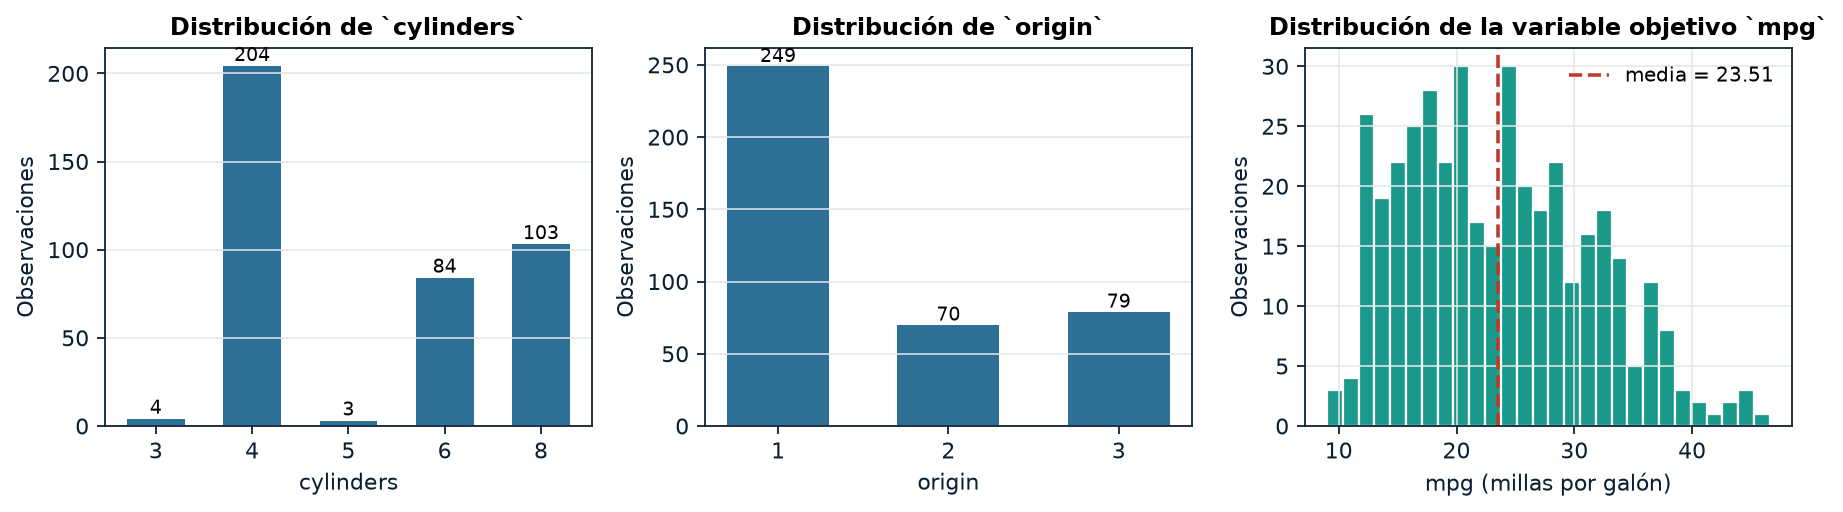

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(11.4, 3.3))

for ax, variable in zip(axes[:2], ["cylinders", "origin"]):
    conteo = df_am[variable].value_counts().sort_index()
    barras = ax.bar([str(i) for i in conteo.index], conteo.values,
                    color=PALETA["azul_claro"], width=0.6)
    ax.set_xlabel(variable)
    ax.set_ylabel("Observaciones")
    ax.set_title(f"Distribución de `{variable}`")
    ax.grid(axis="x", visible=False)
    for b, v in zip(barras, conteo.values):
        ax.text(b.get_x() + b.get_width() / 2, v + 3, str(v), ha="center", fontsize=8.5)

ax = axes[2]
ax.hist(df_am["mpg"], bins=28, color=PALETA["turquesa"], edgecolor="white")
ax.axvline(df_am["mpg"].mean(), color=PALETA["rojo"], linewidth=1.6,
            linestyle="--", label=f"media = {df_am['mpg'].mean():.2f}")
ax.set_xlabel("mpg (millas por galón)")
ax.set_ylabel("Observaciones")
ax.set_title("Distribución de la variable objetivo `mpg`")
ax.legend()

fig.tight_layout()
fig.savefig(RAIZ / "figuras" / "grafico_05_distribuciones_auto_mpg.png")
plt.show()

## 3.5 Correlación con la variable objetivo

In [16]:
matriz = df_am[["mpg", "cylinders", "displacement", "horsepower", "weight",
                "acceleration", "model_year", "origin"]].corr()
print("Matriz de correlación de Pearson:")
print(matriz.round(3).to_string())

Matriz de correlación de Pearson:
                mpg  cylinders  displacement  horsepower  weight  acceleration  model_year  origin
mpg           1.000     -0.775        -0.804      -0.778  -0.832         0.420       0.579   0.563
cylinders    -0.775      1.000         0.951       0.843   0.896        -0.505      -0.349  -0.563
displacement -0.804      0.951         1.000       0.897   0.933        -0.544      -0.370  -0.609
horsepower   -0.778      0.843         0.897       1.000   0.865        -0.689      -0.416  -0.455
weight       -0.832      0.896         0.933       0.865   1.000        -0.417      -0.307  -0.581
acceleration  0.420     -0.505        -0.544      -0.689  -0.417         1.000       0.288   0.206
model_year    0.579     -0.349        -0.370      -0.416  -0.307         0.288       1.000   0.181
origin        0.563     -0.563        -0.609      -0.455  -0.581         0.206       0.181   1.000


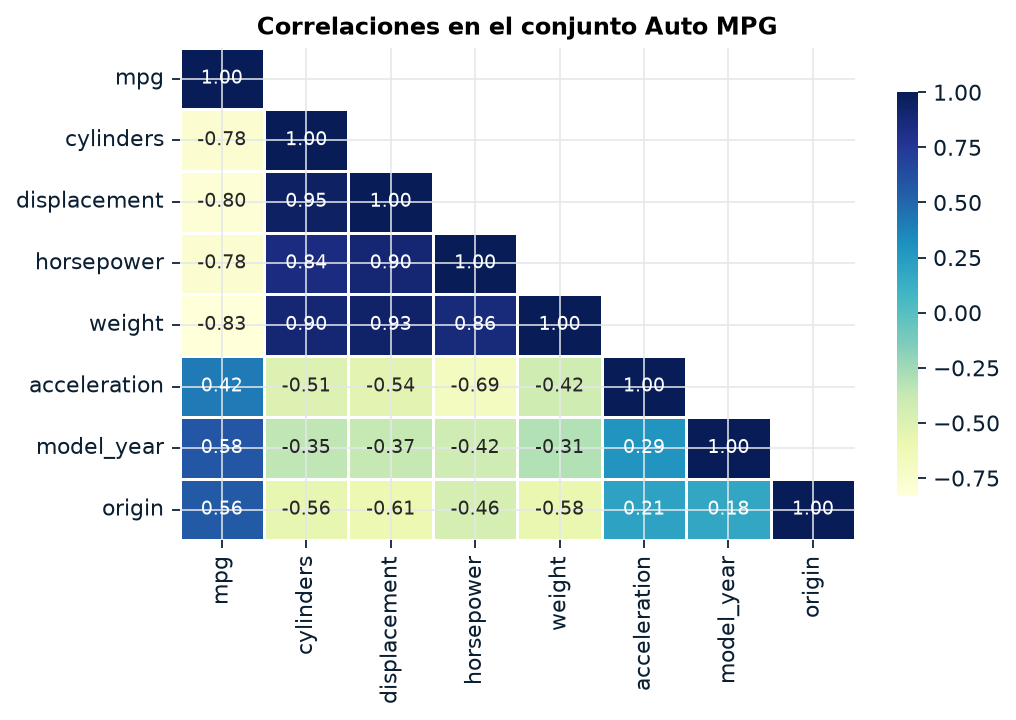

In [17]:
fig, ax = plt.subplots(figsize=(6.6, 4.6))
mascara = np.triu(np.ones_like(matriz, dtype=bool), k=1)
sns.heatmap(matriz, mask=mascara, cmap="YlGnBu", annot=True, fmt=".2f",
            linewidths=0.6, linecolor="white", cbar_kws={"shrink": 0.82},
            ax=ax, annot_kws={"fontsize": 8.5})
ax.set_title("Correlaciones en el conjunto Auto MPG")
fig.tight_layout()
fig.savefig(RAIZ / "figuras" / "grafico_06_matriz_correlacion_auto_mpg.png")
plt.show()

## 3.6 Relación entre las variables predictoras y `mpg`

Se observa una relación claramente no lineal entre el peso y el consumo, lo que anticipa
que un árbol de decisión pueda superar a un modelo lineal en este conjunto.

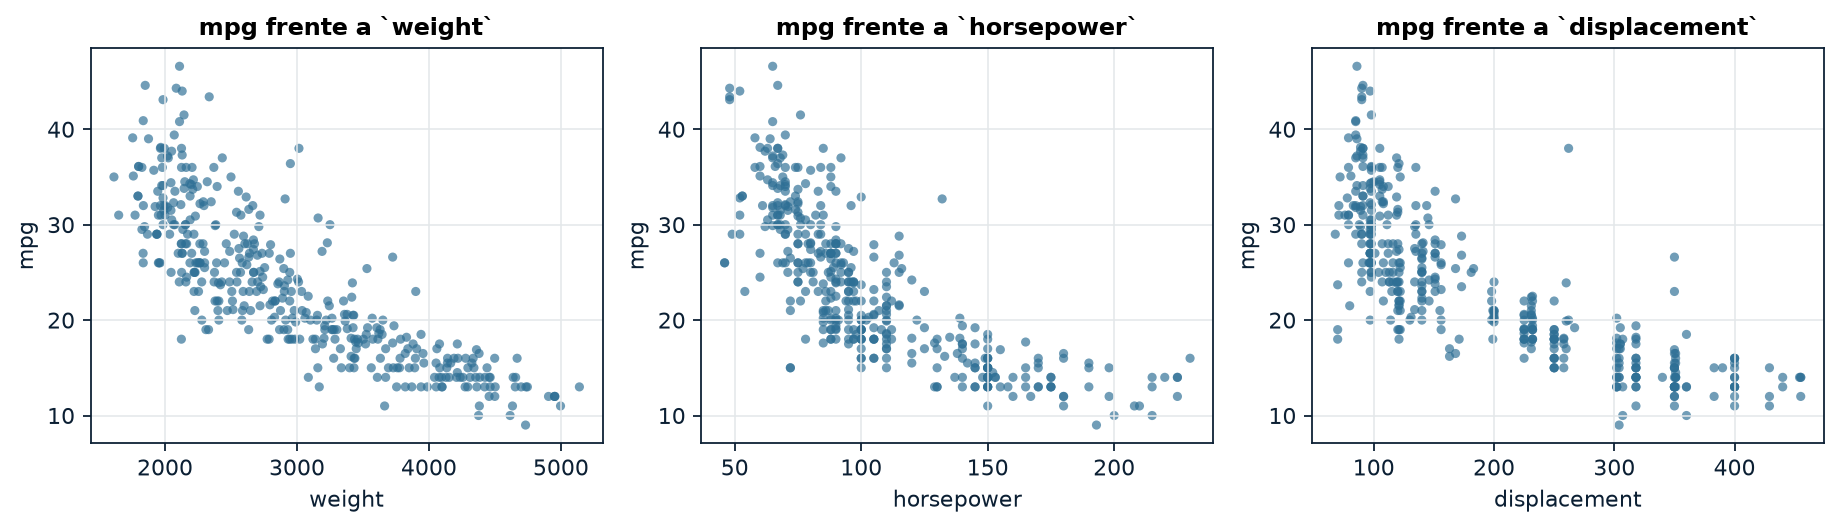

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(11.6, 3.4))
for ax, variable in zip(axes, ["weight", "horsepower", "displacement"]):
    ax.scatter(df_am[variable], df_am["mpg"], s=17, alpha=0.68,
               color=PALETA["azul_claro"], edgecolor="none")
    ax.set_xlabel(variable)
    ax.set_ylabel("mpg")
    ax.set_title(f"mpg frente a `{variable}`")
fig.tight_layout()
fig.savefig(RAIZ / "figuras" / "grafico_07_mpg_versus_predictores.png")
plt.show()

## 3.7 Decisiones de preprocesamiento

| Paso | Justificación |
|---|---|
| Exclusión de `car_name` | Es un identificador nominal del vehículo; puede actuar como atajo (*leakage*) y no aporta información numérica generalizable. |
| Imputación de `horsepower` con la **mediana** | Seis valores ausentes; la mediana es robusta a los valores extremos de este atributo. Se aplica dentro de un `Pipeline`, de modo que la imputación se aprende solo con los datos de entrenamiento de cada partición. |
| Codificación *one-hot* de `origin` | Variable categórica nominal (USA, Europa, Japón) sin orden intrínseco. |
| Estandarización para el modelo lineal | La regresión lineal es sensible a la escala; el escalado se realiza dentro del `Pipeline` de preprocesamiento. |

Los árboles de decisión no requieren estandarización ni imputación explícita (gestionan
valores faltantes de forma nativa), pero se les aplica el mismo `Pipeline` para que todas
las comparaciones se apoyen sobre datos idénticos.

In [19]:
from sklearn.model_selection import train_test_split

X_tr_am, X_te_am, y_tr_am, y_te_am = train_test_split(
    X_am, y_am, test_size=0.20, random_state=SEMILLA
)

print(f"Auto MPG — entrenamiento: {X_tr_am.shape[0]} vehículos, prueba: {X_te_am.shape[0]} vehículos")
print(f"Media de mpg — entrenamiento: {y_tr_am.mean():.3f}")
print(f"Media de mpg — prueba:        {y_te_am.mean():.3f}")
print(f"Desviación típica de mpg — prueba: {y_te_am.std():.3f}")

Auto MPG — entrenamiento: 318 vehículos, prueba: 80 vehículos
Media de mpg — entrenamiento: 23.608
Media de mpg — prueba:        23.143
Desviación típica de mpg — prueba: 7.379


# 4. Resumen de la exploración

In [20]:
resumen = pd.DataFrame(
    [
        {
            "conjunto": "breast_cancer",
            "tipo_problema": "clasificación binaria",
            "observaciones": df_bc.shape[0],
            "variables_predictoras": len(nombres_bc),
            "variable_objetivo": "diagnostico (0 benigno / 1 maligno)",
            "valores_faltantes": int(df_bc.isna().sum().sum()),
            "particion_prueba": f"{X_te.shape[0]} observaciones (20 %, estratificada)",
        },
        {
            "conjunto": "auto_mpg",
            "tipo_problema": "regresión",
            "observaciones": df_am.shape[0],
            "variables_predictoras": X_am.shape[1],
            "variable_objetivo": "mpg (millas por galón)",
            "valores_faltantes": int(df_am.isna().sum().sum()),
            "particion_prueba": f"{X_te_am.shape[0]} vehículos (20 %)",
        },
    ]
)
display(resumen)
guardar_csv(resumen, "resumen_exploracion.csv")

,conjunto,tipo_problema,observaciones,variables_predictoras,variable_objetivo,valores_faltantes,particion_prueba
0,breast_cancer,clasificación binaria,569,30,diagnostico (0 benigno / 1 maligno),0,"114 observaciones (20 %, estratificada)"
1,auto_mpg,regresión,398,7,mpg (millas por galón),6,80 vehículos (20 %)


PosixPath('/home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 3/resultados/resumen_exploracion.csv')

# 5. Conclusiones del cuaderno 01

1. **`breast_cancer`** contiene 569 observaciones y 30 variables numéricas sin valores
   faltantes ni duplicados. La clase malignancy representa el 37,3 % del total, de modo que
   el desbalance es moderado y justifica evaluar con F1 además de la exactitud.
2. Las variables `worst radius` y `worst concave points` concentran la mayor correlación
   con el diagnóstico, lo que anticipa que los árboles de decisión las utilicen en las
   primeras particiones.
3. **`auto_mpg`** contiene 398 vehículos y 7 predictores (más `car_name`, que se descarta).
   Los seis valores faltantes de `horsepower` se imputan con la mediana dentro de un
   `Pipeline`, evitando fuga de información.
4. La relación entre `mpg` y el peso del vehículo es claramente no lineal, lo que sugiere
   que un modelo de árbol puede superar a la regresión lineal en el ejercicio 2.
5. La partición 80/20 con semilla 42 y estratificación se fija **una sola vez** y se
   reutiliza en todos los ejercicios, de modo que las comparaciones entre modelos sean
   consistentes.

In [21]:
print("Cuaderno 01 finalizado correctamente.")

Cuaderno 01 finalizado correctamente.
